In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt    # 통계 그래프 라이브러리
import seaborn as sns


plt.rcParams["font.family"] = "Malgun Gothic"

df = sns.load_dataset("diamonds")
print(df.shape)
df.info()
# df.describe()

(53940, 10)
<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [2]:
df.describe()

# 평균이 더 큼 이 차이는 평균값을 유의미하게 만들지 못하게 하는 이상치 값들이 있을 수 있다는 것임

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [3]:
zero_mask = (df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0)
print(f"\n[2] 셋 중 하나라도 0인 행 수: {zero_mask.sum()}")
df[zero_mask]


[2] 셋 중 하나라도 0인 행 수: 20


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0
15951,1.14,Fair,G,VS1,57.5,67.0,6381,0.00,0.00,0.0
24394,2.18,Premium,H,SI2,59.4,61.0,12631,8.49,8.45,0.0


In [4]:
big_mask = (df["y"] > 20) | (df["z"] > 20)
print(f"\n[3] y 또는 z가 20mm 초과인 행 수: {big_mask.sum()}")
df[big_mask]


[3] y 또는 z가 20mm 초과인 행 수: 3


,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [5]:
clean = df[~(zero_mask | big_mask)].copy()
print(f"\n[4] 제거 전 행 수: {len(df)}")
print(f"    제거 후 행 수: {len(clean)}")
print(f"    제거된 행 수: {len(df) - len(clean)}")

# 머신러닝에 방해 될 수 있는 빈칸을 지웠음
# 실제로 비싼 다이아몬드는 존재해서


[4] 제거 전 행 수: 53940
    제거 후 행 수: 53917
    제거된 행 수: 23


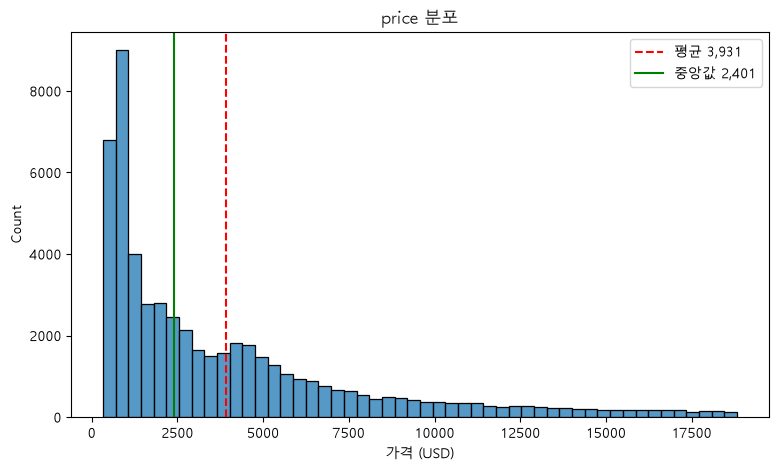

평균: 3,930.9 / 중앙값: 2,401.0


In [6]:
price_mean = clean["price"].mean()
price_median = clean["price"].median()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=clean, x="price", bins=50, ax=ax)
ax.axvline(price_mean, color="red", linestyle="--", label=f"평균 {price_mean:,.0f}")
ax.axvline(price_median, color="green", linestyle="-", label=f"중앙값 {price_median:,.0f}")
ax.set_title("price 분포")
ax.set_xlabel("가격 (USD)")
ax.legend()
plt.show()

print(f"평균: {price_mean:,.1f} / 중앙값: {price_median:,.1f}")

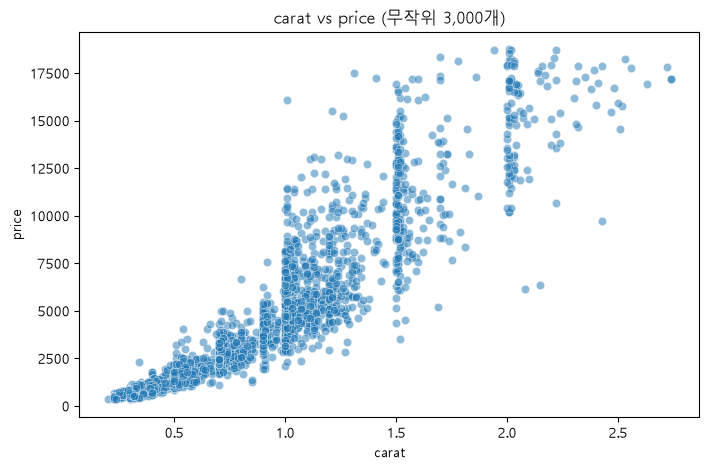

In [7]:
sample = clean.sample(3000, random_state=42)

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=sample, x="carat", y="price", alpha=0.5, ax=ax)
ax.set_title("carat vs price (무작위 3,000개)")
plt.show()

In [8]:
corr = clean.select_dtypes("number").corr()
price_corr = corr["price"].sort_values(ascending=False)
print(price_corr)

# price와 상관계수가 숫자열 중 가장 높아서
# carat이 커질 수 록 퍼져서 직선 맞추기 어려움
# 그리고 0.5 마다 새로로 분포해서 직선 사용 어려움

price    1.000000
carat    0.921586
y        0.888818
x        0.887221
z        0.882107
table    0.127241
depth   -0.010653
Name: price, dtype: float64


In [9]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(clean[["carat"]], clean["price"])

w = model.coef_[0]
b = model.intercept_
print(f"w (기울기): {w:,.1f}")
print(f"b (절편)  : {b:,.1f}")

w (기울기): 7,755.9
b (절편)  : -2,255.9


### w는 1케럿당 오르는 가격의 수치정도
### 데이터 값에 따라 정확도는 나뉨

In [10]:
new_data = pd.DataFrame({"carat": [0.25, 0.5, 1.0, 2.0]})
pred = model.predict(new_data)

for c, p in zip(new_data["carat"], pred):
    print(f"{c:>4} 캐럿 → 예측 가격 {p:>10,.0f} 달러")


# 그래프는 계속 일직선인데 실제 가격은 작은 캐럿에서 완만하게 휘어서 0 근처로 모이는 휘어짐을 못 따라가서 절편(b)가 음수가 돼서


0.25 캐럿 → 예측 가격       -317 달러
 0.5 캐럿 → 예측 가격      1,622 달러
 1.0 캐럿 → 예측 가격      5,500 달러
 2.0 캐럿 → 예측 가격     13,256 달러
